TokaMaker Meshing Example: Building a mesh for TCS {#doc_tMaker_TCS_ex1}
==========
In this example we show how to generate a mesh for the confinement section of the Translation, Confinement, and Sustainment (TCS) field-reversed configuration (FRC) experiment [[A. L. Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205)] using TokaMaker's built in mesh generation.

**Note:** Running this example requires the [h5py](https://www.h5py.org/) python packages, which is installable using `pip` or other standard methods.

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize']=(6,6)
plt.rcParams['font.weight']='bold'
plt.rcParams['axes.labelweight']='bold'
plt.rcParams['lines.linewidth']=2
plt.rcParams['lines.markeredgewidth']=2
%matplotlib inline
%config InlineBackend.figure_format = "retina"

### Load TokaMaker library

To load the TokaMaker python module we need to tell python where to the module is located. This can be done either through the `PYTHONPATH` environment variable or using within a script using `sys.path.append()` as below, where we look for the environement variable `OFT_ROOTPATH` to provide the path to where the OpenFUSIONToolkit is installed (`/Applications/OFT` on macOS).

For meshing we will use the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain "gs_Domain" class to build a 2D triangular grid suitable for Grad-Shafranov equilibria. This class uses the [triangle code](https://www.cs.cmu.edu/~quake/triangle.html) through a simple internal python wrapper within OFT.

In [2]:
tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path,'python'))
from OpenFUSIONToolkit.TokaMaker.meshing import gs_Domain, save_gs_mesh

# Build mesh

## Set mesh resolution for each region
First we define some target sizes to set the resolution in our grid. These variables will be used later and represent the target edge size within a given region, where units are in meters. Note that when setting up a new machine these values will need to scale with the overall size of the device/domain. Additionally, one should perform a convergence study, by increasing resolution (decreasing target size) by at least a factor of two in all regions to ensure the results are not sensitive to your choice of grid size.

In [3]:
plasma_dx = 0.015
coil_dx = 0.01
vac_dx = 0.05

## Define geometry
The geometry of TCS is simple enough that we define it directly here, using the description in Sec. III of [Hoffman et al. (2002)](https://doi.org/10.13182/FST02-A205). Only the confinement section of TCS is included and the plasma region is closed off at the end of the transition cones, where the vessel would otherwise connect to the 27-cm-diameter exit tubes.

 - **Plasma tube:** The plasma chamber is formed from two 1.25-m-long quartz tubes with an 80-cm inside diameter, joined by a short central section. At each end, 45-degree stainless steel cones transition to 27-cm-diameter tubes. Here we use a 2.6 m long straight section.
 - **Axial confinement coils:** There are twenty 56-turn coils with a 47 cm mean radius and a 5 x 5 cm cross-section. The central 14 coils are powered together to act as a flux conserver, while the outer three coils on each end are powered by a separate bank. The axial spacing (13 cm) is estimated from the statement that the 1.5-m-long RMF antennas cover the inner 12 coils.
 - **Cone mirror coils:** Two 121-turn mirror coils with a radius of ~35 cm surround the transition cones. Their cross-section and axial position are estimated from Fig. 4 of the paper.

**Note:** The RMF antennas, which are not axisymmetric, are not included. Additionally, the 1.6 mm stainless steel coil liners and cones are not included as conducting structures in this example.

In [4]:
# Plasma tube (quartz tubes + 45-degree transition cones)
tube_r = 0.40   # Inner radius of quartz plasma tube
tube_hl = 1.30  # Half-length of the 80-cm-diameter straight section
exit_r = 0.135  # Inner radius of 27-cm-diameter exit tubes
cone_hl = tube_hl + (tube_r-exit_r)  # Half-length to end of 45-degree cones

# Axial confinement coils
axial_rc = 0.47      # Mean radius
axial_w = 0.05       # Radial width
axial_h = 0.05       # Axial height
axial_pitch = 0.13   # Axial spacing between coils
axial_nturns = 56    # Number of turns
axial_zc = (np.arange(20)-9.5)*axial_pitch  # Axial positions

# Cone mirror coils
mirror_rc = 0.35     # Mean radius
mirror_w = 0.10      # Radial width
mirror_h = 0.05      # Axial height
mirror_zc = tube_hl + 0.155  # Axial position (|Z|)
mirror_nturns = 121  # Number of turns

# Plasma region boundary
plasma_boundary = np.array([
    [0.0,     -cone_hl],
    [exit_r,  -cone_hl],
    [tube_r,  -tube_hl],
    [tube_r,   tube_hl],
    [exit_r,   cone_hl],
    [0.0,      cone_hl]
])

## Define regions and attributes
We now create and define the various logical mesh regions. In the TCS case we have 3 types of regions:
 - `air`: The region outside the plasma tube
 - `plasma`: The region inside the plasma tube where the plasma will exist
 - `END1, ..., CENTRAL4, ..., MIRROR1, ...`: Each of the axial confinement and mirror coils

Each coil is defined as an independent coil, with the number of turns set using the `nTurns` argument to \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.define_region "define_region()". In TCS the coils within each group (`CENTRAL`, `END`, and `MIRROR`) are wired in parallel, so their currents can differ from one another as flux is redistributed (eg. the flux conserver effect when an FRC enters the chamber). As a result, we do not use the `coil_set` argument to join them, which would force all coils in a given set to carry the same current. The coil names still indicate which group each coil belongs to:
 - `CENTRAL4, ..., CENTRAL17`: The central 14 axial coils
 - `END1, ..., END3` and `END18, ..., END20`: The outer 3 axial coils on each end
 - `MIRROR1, MIRROR2`: The two cone mirror coils

For each region you can provide a target size and one of four region types:
 - `plasma`: The region where the plasma can exist and the classic Grad-Shafranov equation with $F*F'$ and $P'$ are allowed. **There can only be one region of this type**
 - `vacuum`: A region where no current can flow and $\nabla^* \psi = 0$ is solved
 - `boundary`: A special case of the `vacuum` region, which forms the outer boundary of the computational domain. **A region of this type is required if more than one region is specified**
 - `conductor`: A region where toroidal current can flow passively (no externally applied voltage). For this type of region the resistivity should be specified with the argument `eta` in units of $\omega \mathrm{-m}$.
 - `coil`: A region where toroidal current can flow with specified amplitude through \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_currents "set_coil_currents()" or via shape optimization \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_coil_reg "set_coil_reg()" and \ref OpenFUSIONToolkit.TokaMaker.TokaMaker.set_isoflux "set_isoflux()"

In [5]:
# Create a G-S domain
gs_mesh = gs_Domain()
# Define region information for mesh
gs_mesh.define_region('air',vac_dx,'boundary')      # Define the bounding region
gs_mesh.define_region('plasma',plasma_dx,'plasma')  # Define the plasma region and resolution

# Define each of the axial and mirror coils
axial_names = []
for i in range(axial_zc.shape[0]):
    if (i < 3) or (i >= axial_zc.shape[0]-3):
        coil_group = 'END'
    else:
        coil_group = 'CENTRAL'
    axial_names.append('{0}{1}'.format(coil_group,i+1))
    gs_mesh.define_region(axial_names[-1],coil_dx,'coil',nTurns=axial_nturns)
for i in range(2):
    gs_mesh.define_region('MIRROR{0}'.format(i+1),coil_dx,'coil',nTurns=mirror_nturns)

## Define geometry for region boundaries
Once the region types and properties are defined we now define the geometry of the mesh using shapes and references to the defined regions.
 1. We add the plasma tube contour as a "polygon", referencing `plasma` as the region enclosed by the contour and `air` as the region outside the contour.
 2. We add each of the coils as "rectangles", which are defined by a center point (R,Z) along with a width (W) and height (H). We also reference `air` as the region outside the rectangle for all coils.
 3. We manually specify a boundary contour, with points where the plasma region intersects $R=0$, to ensure proper handling of region overlaps on the axis.

In [6]:
# Define plasma region
gs_mesh.add_polygon(plasma_boundary,'plasma',parent_name='air')

# Define the shape of the axial and mirror coils
for i, zc in enumerate(axial_zc):
    gs_mesh.add_rectangle(axial_rc,zc,axial_w,axial_h,axial_names[i],parent_name='air')
for i, zc in enumerate((-mirror_zc,mirror_zc)):
    gs_mesh.add_rectangle(mirror_rc,zc,mirror_w,mirror_h,'MIRROR{0}'.format(i+1),parent_name='air')

# Define outer boundary path with points at the plasma region intersection with R=0
domain_r = 0.8
domain_hl = 2.0
boundary_path = np.array([
    [0.0,      -cone_hl],
    [0.0,      -domain_hl],
    [domain_r, -domain_hl],
    [domain_r,  domain_hl],
    [0.0,       domain_hl],
    [0.0,       cone_hl]
])
gs_mesh.add_polygon(boundary_path,'air')

## Plot topology
After defining the logical and physical topology we can now plot the curves within the definitions to double check everything is in the right place. As the device is long and thin we plot with the axis of symmetry ($Z$) along the horizontal axis.

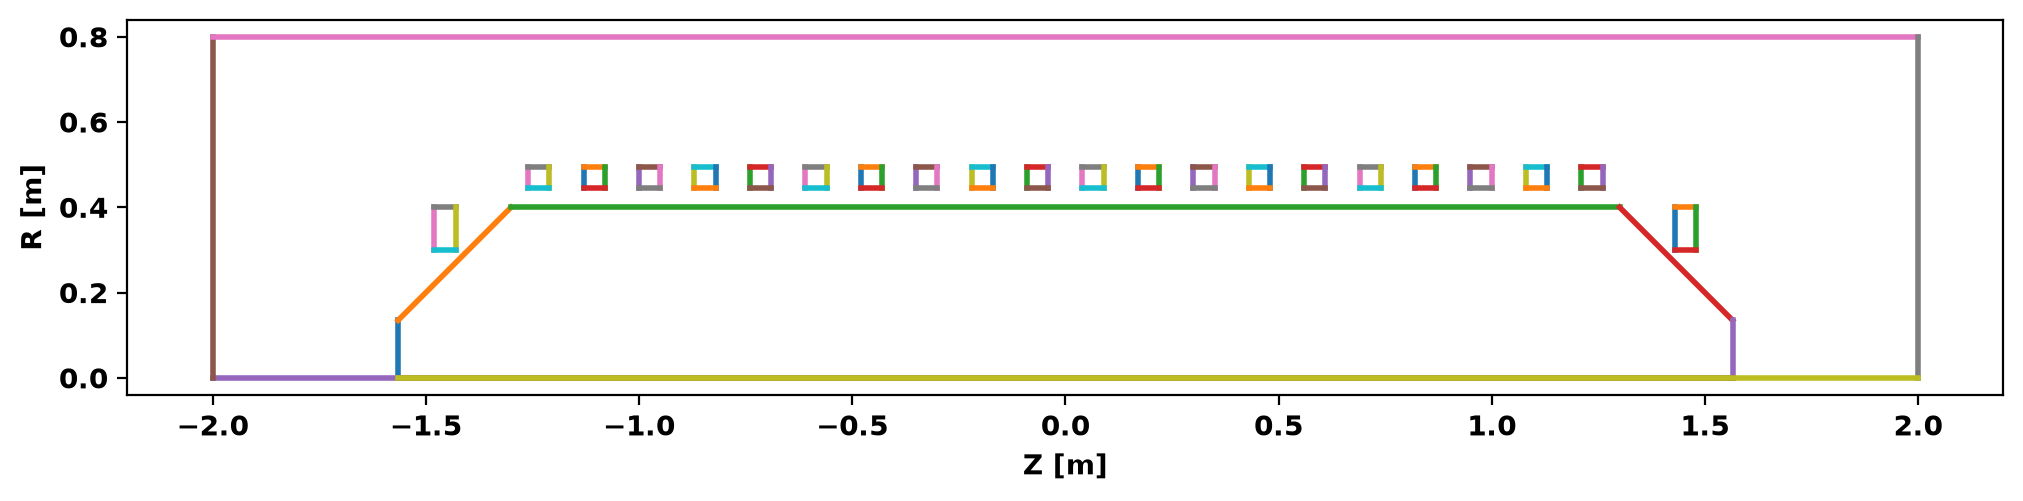

In [7]:
fig, ax = plt.subplots(1,1,figsize=(10,3),constrained_layout=True)
gs_mesh.plot_topology(fig,ax,rotate=True)
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel('R [m]')

## Create mesh
Now we generate the actual mesh using the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.build_mesh "build_mesh()" method. Additionally, if `coil` and/or `conductor` regions are defined the \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.get_coils "get_coils()" and \ref OpenFUSIONToolkit.TokaMaker.gs_Domain.get_conductors "get_conductors()" methods should also be called to get descriptive dictionaries for later use in TokaMaker. This step may take a few moments as [triangle](https://www.cs.cmu.edu/~quake/triangle.html) generates the mesh.

Note that, as is common with unstructured meshes, the mesh is stored a list of points `mesh_pts` of size (np,2), a list of cells formed from three points each `mesh_lc` of size (nc,3), and an array providing a region id number for each cell `mesh_reg` of size (nc,), which is mapped to the names above using the `coil_dict` and `cond_dict` dictionaries.

In [8]:
mesh_pts, mesh_lc, mesh_reg = gs_mesh.build_mesh()
coil_dict = gs_mesh.get_coils()
cond_dict = gs_mesh.get_conductors()

Assembling regions:
  # of unique points    = 1006
  # of unique segments  = 99


Generating mesh with Triangle:
  # of points  = 10896
  # of cells   = 21452
  # of regions = 24


## Plot resulting regions and grid
We now plot the mesh by region to inspect proper generation, including a zoomed view of one of the transition cones. As each coil is an independent region, legends are disabled to keep the plots readable.

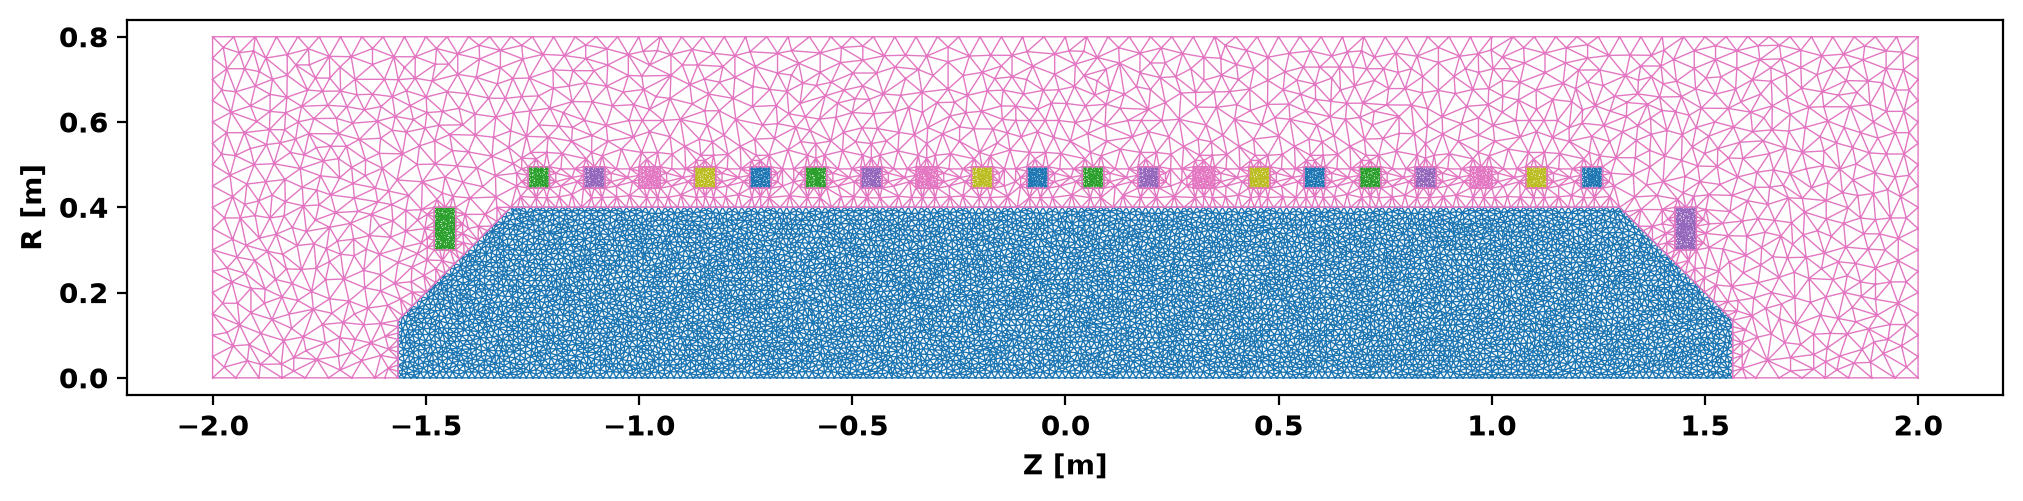

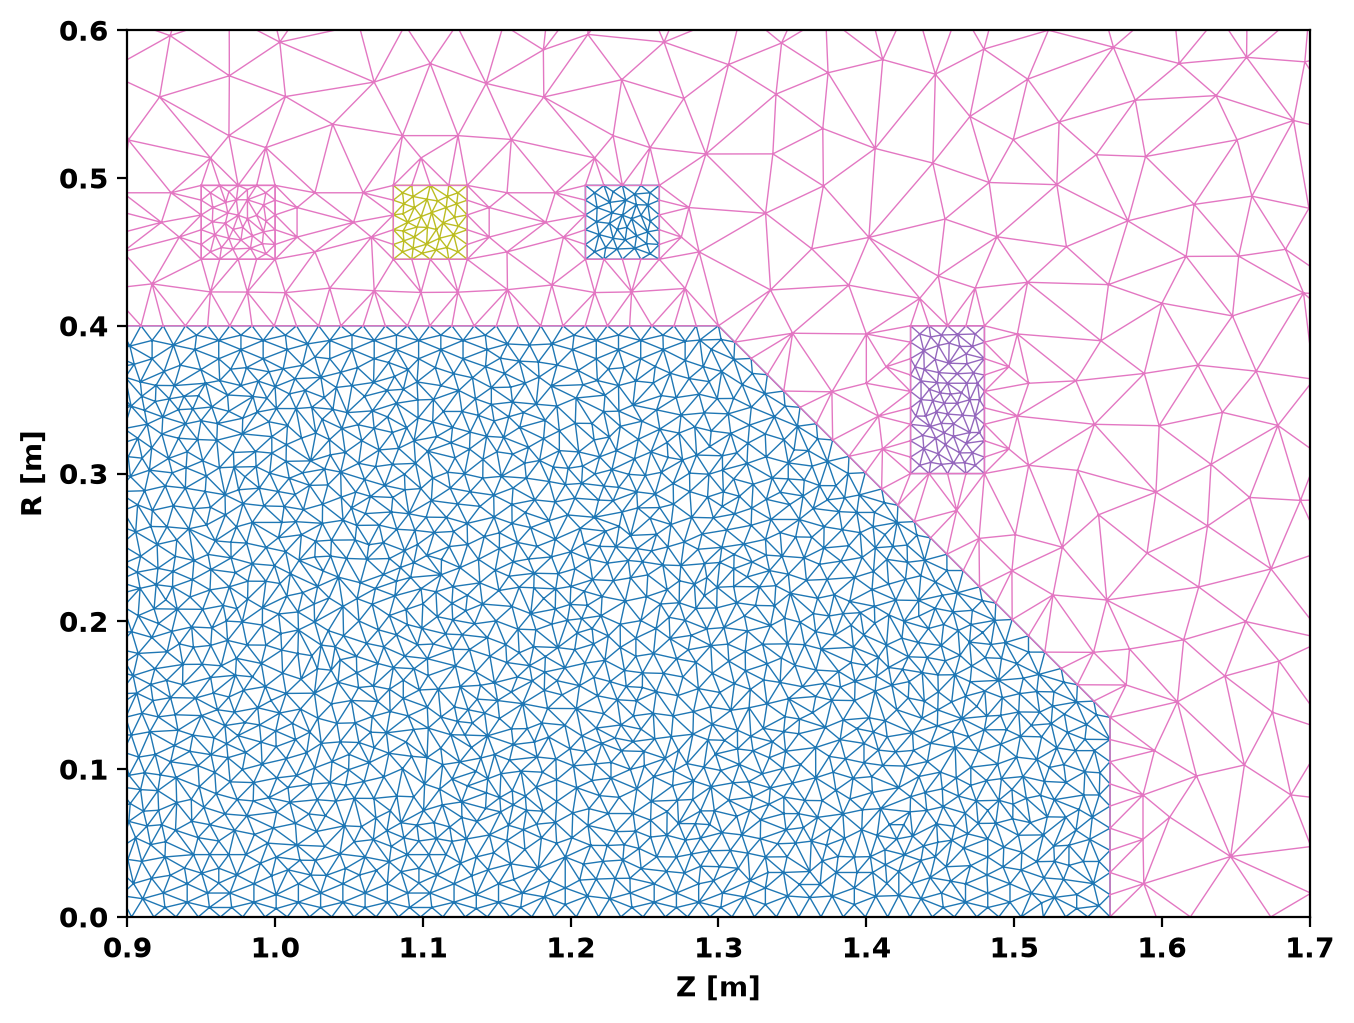

In [9]:
fig, ax = plt.subplots(1,1,figsize=(10,3),constrained_layout=True)
gs_mesh.plot_mesh(fig,ax,rotate=True,show_legends=False)
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel('R [m]')

fig, ax = plt.subplots(1,1,figsize=(10,5),constrained_layout=True)
gs_mesh.plot_mesh(fig,ax,rotate=True,show_legends=False)
ax.set_xlim(0.9,1.7)
ax.set_ylim(0.0,0.6)
ax.set_xlabel('Z [m]')
_ = ax.set_ylabel('R [m]')

## Save mesh for later use
As generation of the mesh often takes comparable, or longer, time compare to runs in TokaMaker it is useful to separate generation of the mesh into a different script as demonstrated here. The method \ref OpenFUSIONToolkit.TokaMaker.save_gs_mesh "save_gs_mesh()" can be used to save the resulting information for later use. This is done using and an [HDF5](https://www.hdfgroup.org/solutions/hdf5/) file through the [h5py](https://www.h5py.org/) library.

In [10]:
save_gs_mesh(mesh_pts,mesh_lc,mesh_reg,coil_dict,cond_dict,'TCS_mesh.h5')